# Лабораторная работа №3

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

df = pd.read_csv("StudentsPerformance.csv")

display(df.head())
df.info()

numeric_cols = ["math score", "reading score", "writing score"]

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


## Pandas

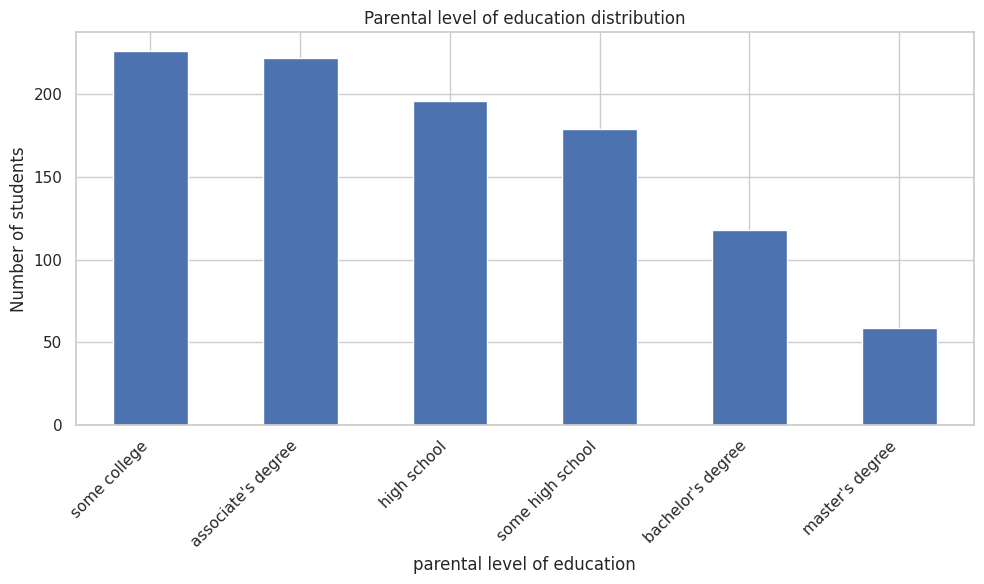

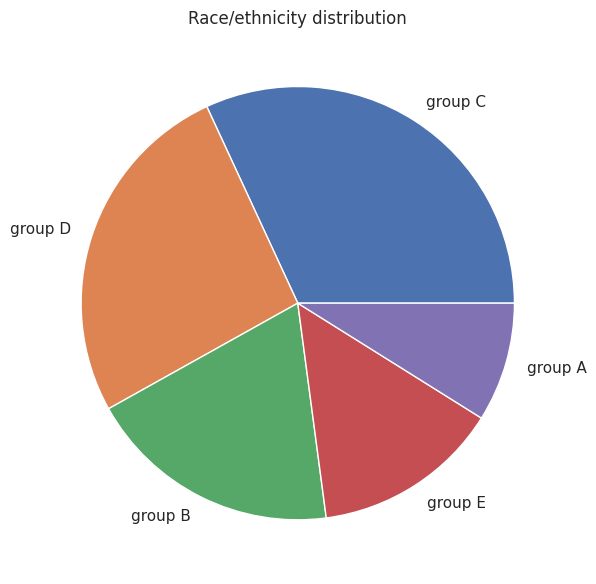

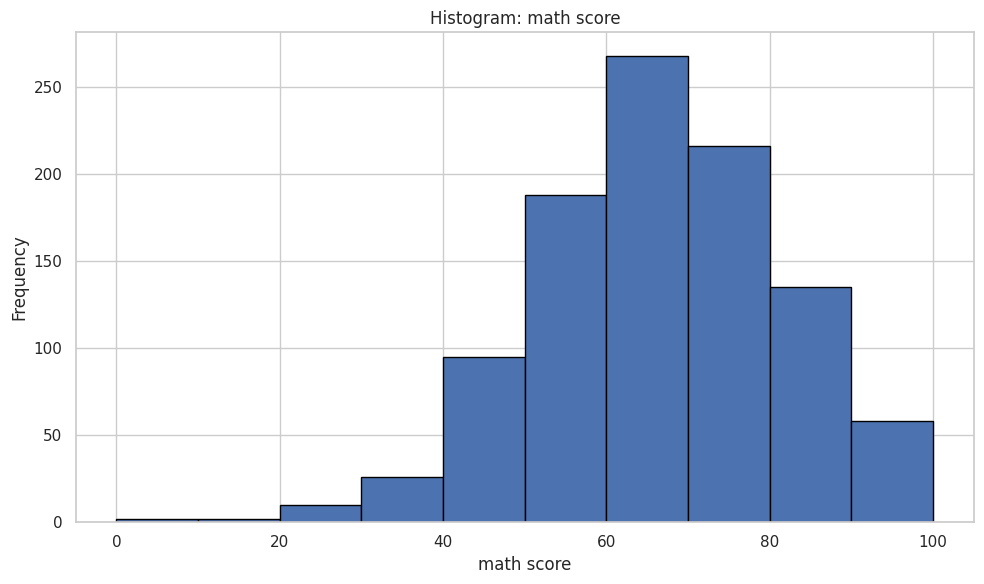

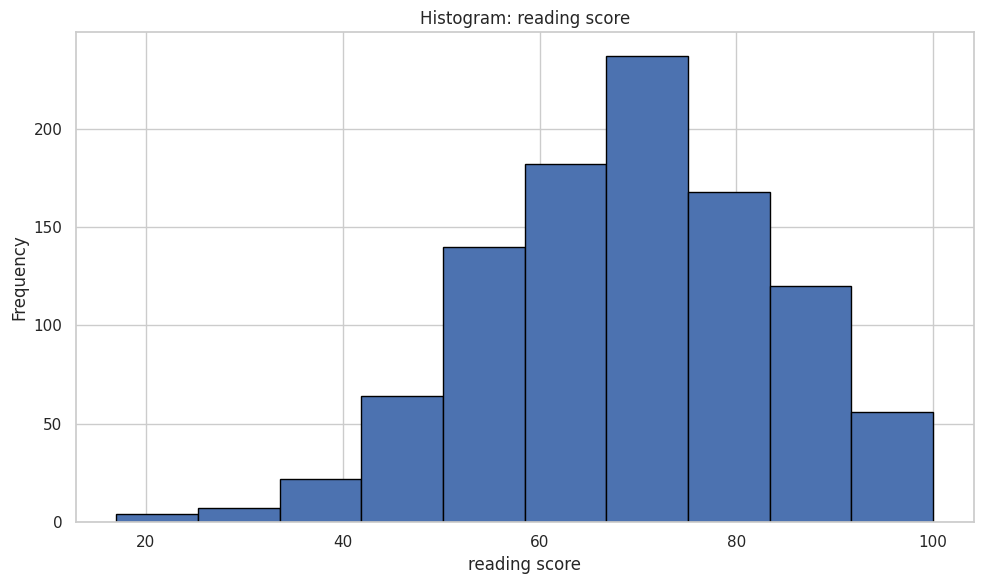

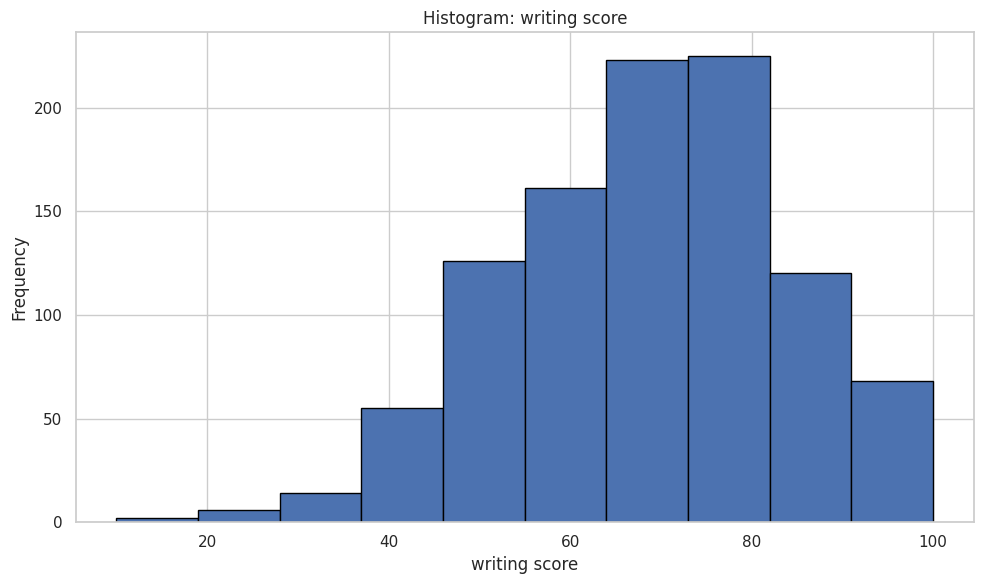

In [ ]:
# 1. Столбчатая диаграмма parental level of education
plt.figure()
df["parental level of education"].value_counts().plot(kind="bar")
plt.title("Parental level of education distribution")
plt.xlabel("parental level of education")
plt.ylabel("Number of students")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 2. Круговая диаграмма race/ethnicity
plt.figure()
df["race/ethnicity"].value_counts().plot(
    kind="pie",
    ylabel=""
)
plt.title("Race/ethnicity distribution")
plt.tight_layout()
plt.show()

# 3. Гистограммы для числовых столбцов
for col in numeric_cols:
    plt.figure()
    df[col].hist(bins=10, edgecolor="black")
    plt.title(f"Histogram: {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

Были построены:
1. Столбчатая диаграмма для parental level of education
2. Круговая диаграмма для race/ethnicity
3. Гистограммы для числовых столбцов math score, reading score, writing score

## Matplotlib

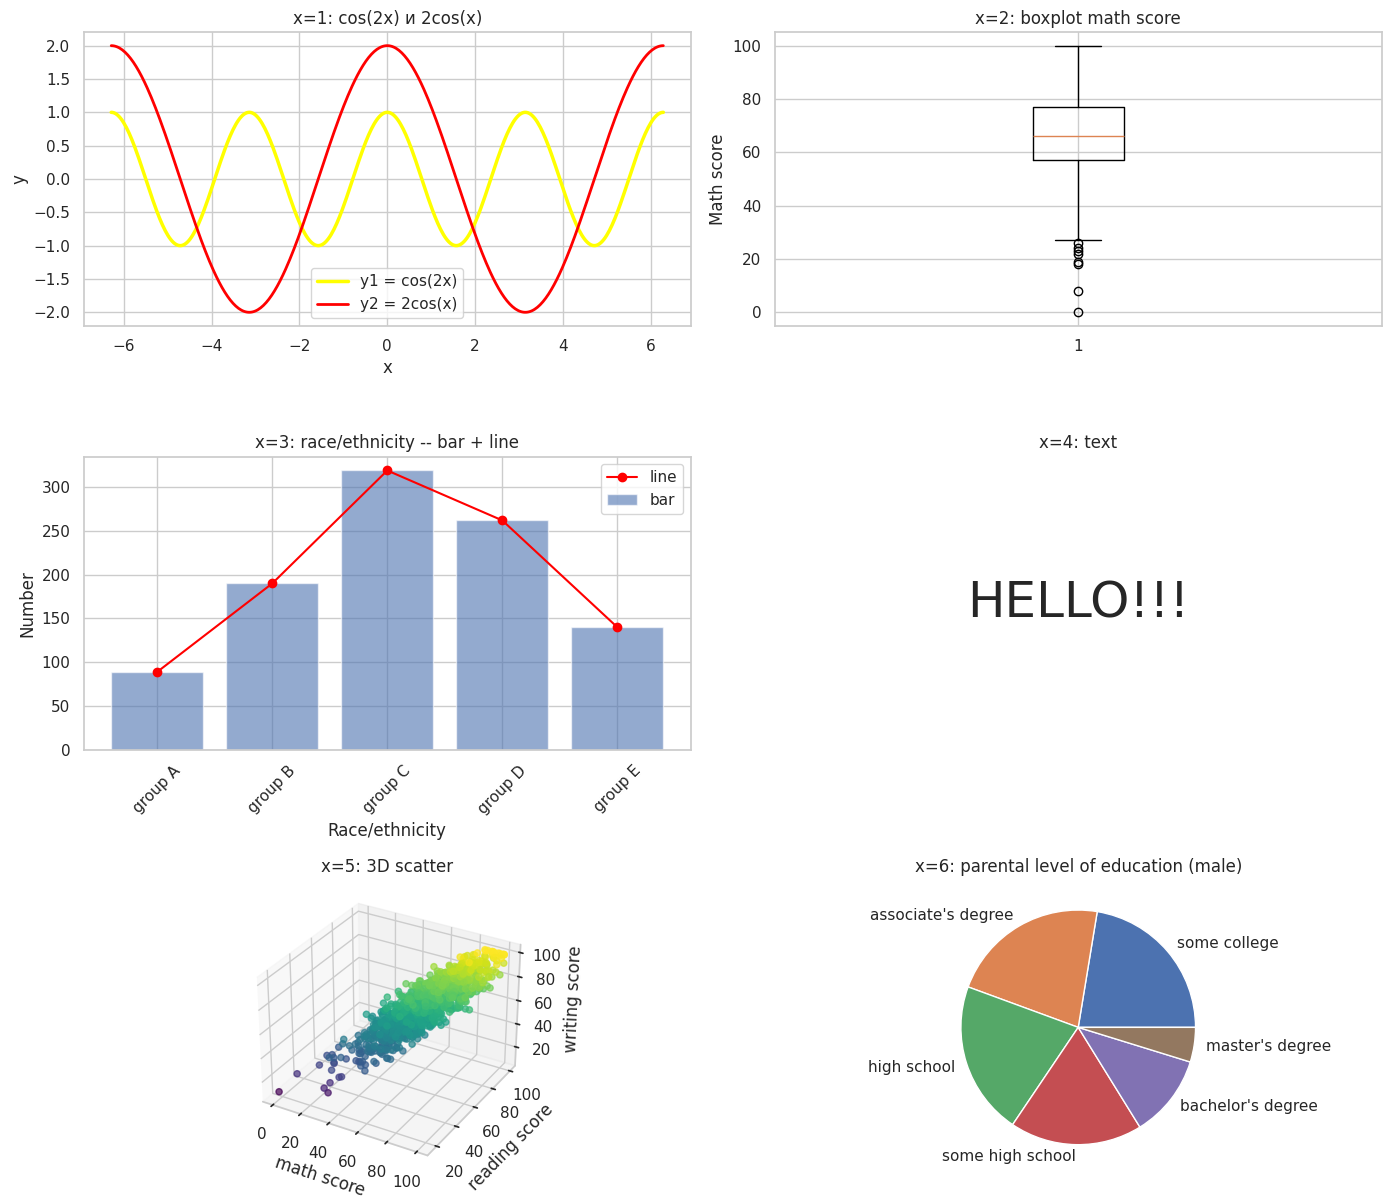

In [ ]:
x = np.linspace(-2 * np.pi, 2 * np.pi, 400)

fig = plt.figure(figsize=(14, 12))

#x=1 Графики функций
ax1 = fig.add_subplot(3, 2, 1)
ax1.plot(x, np.cos(2 * x), color="yellow", linewidth=2.5, label="y1 = cos(2x)")
ax1.plot(x, 2 * np.cos(x), color="red", linewidth=2, label="y2 = 2cos(x)")
ax1.set_title("x=1: cos(2x) и 2cos(x)")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.grid(True)
ax1.legend()

#x=2 Ящик с усами math score
ax2 = fig.add_subplot(3, 2, 2)
ax2.boxplot(df["math score"])
ax2.set_title("x=2: boxplot math score")
ax2.set_ylabel("Math score")
ax2.grid(True)

#x=3 Комбинированный график race/ethnicity
ax3 = fig.add_subplot(3, 2, 3)
race_counts = df["race/ethnicity"].value_counts().sort_index()
ax3.bar(race_counts.index, race_counts.values, alpha=0.6, label="bar")
ax3.plot(race_counts.index, race_counts.values, color="red", marker="o", label="line")
ax3.set_title("x=3: race/ethnicity -- bar + line")
ax3.set_xlabel("Race/ethnicity")
ax3.set_ylabel("Number")
ax3.tick_params(axis="x", rotation=45)
ax3.legend()
ax3.grid(True)

#x=4 Текст HELLO!!!
ax4 = fig.add_subplot(3, 2, 4)
ax4.text(0.5, 0.5, "HELLO!!!", ha="center", va="center", fontsize=36)
ax4.set_title("x=4: text")
ax4.axis("off")

#x=5 3D-диаграмма рассеяния
ax5 = fig.add_subplot(3, 2, 5, projection="3d")
ax5.scatter(
    df["math score"],
    df["reading score"],
    df["writing score"],
    c=df["writing score"],
    cmap="viridis",
    alpha=0.7
)
ax5.set_title("x=5: 3D scatter")
ax5.set_xlabel("math score")
ax5.set_ylabel("reading score")
ax5.set_zlabel("writing score")

#x=6 Круговая диаграмма parental level of education только для male
ax6 = fig.add_subplot(3, 2, 6)
male_edu = df[df["gender"] == "male"]["parental level of education"].value_counts()
ax6.pie(male_edu.values, labels=male_edu.index)
ax6.set_title("x=6: parental level of education (male)")

plt.tight_layout()
plt.show()

In [ ]:
Q1 = df["math score"].quantile(0.25)
Q3 = df["math score"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_math = df[
    (df["math score"] < lower_bound) | (df["math score"] > upper_bound)
]

print(f"Q1 = {Q1}")
print(f"Q3 = {Q3}")
print(f"IQR = {IQR}")
print(f"Нижняя граница = {lower_bound}")
print(f"Верхняя граница = {upper_bound}")
print(f"Количество выбросов по math score: {len(outliers_math)}")

Q1 = 57.0
Q3 = 77.0
IQR = 20.0
Нижняя граница = 27.0
Верхняя граница = 107.0
Количество выбросов по math score: 8


Построены 6 графиков:
1. y1 = cos(2x) и y2 = 2cos(x) на интервале [-2π; 2π]
2. Ящик с усами для math score
3. Комбинированный график для race/ethnicity: столбчатая диаграмма+график
4. Текст HELLO!!!
5. 3D-диаграмма рассеяния по трём оценкам
6. Круговая диаграмма с процентами для parental level of education только среди юношей (gender == "male")

## Seaborn

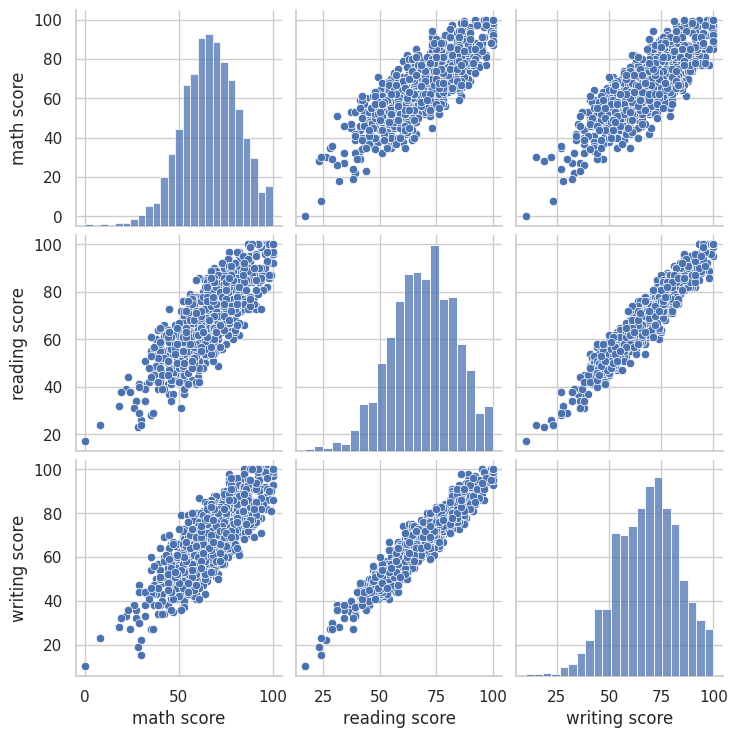

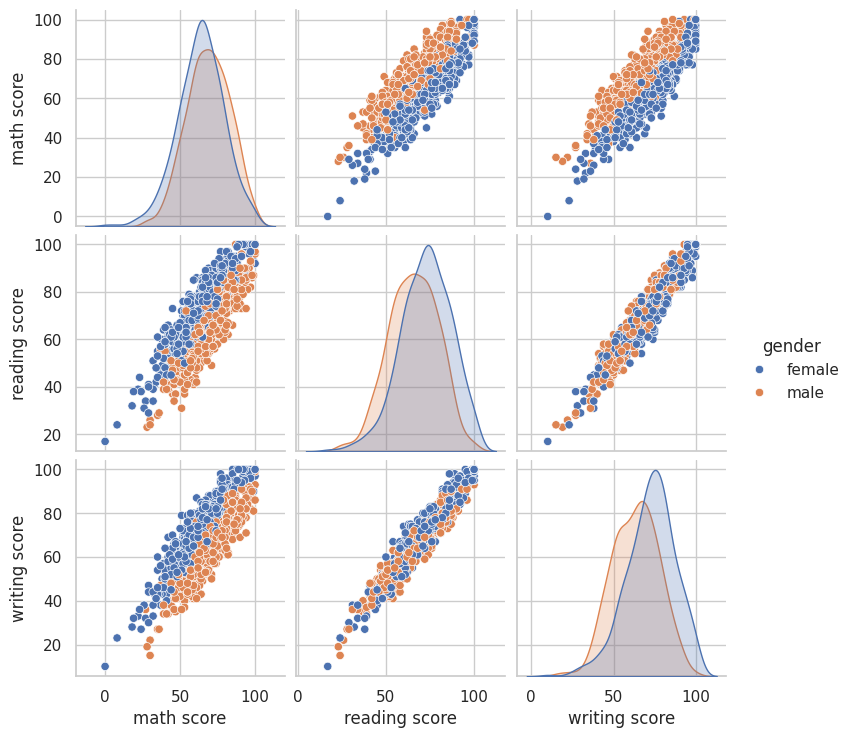

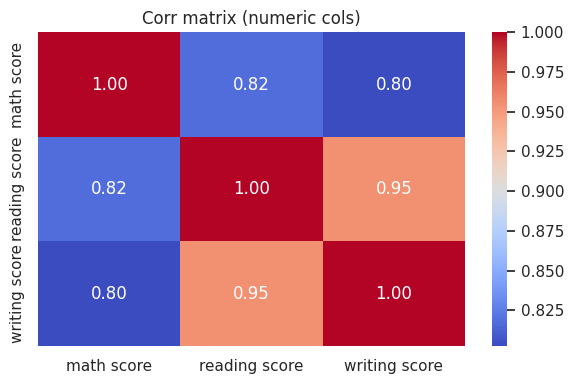

In [ ]:
#1. pairplot: гистограммы по диагонали + scatter
sns.pairplot(df[numeric_cols])
plt.show()

#2. pairplot: kde по диагонали + scatter, hue по gender
sns.pairplot(
    df,
    vars=numeric_cols,
    hue="gender",
    diag_kind="kde"
)
plt.show()

#3. Тепловая карта корреляций
plt.figure(figsize=(6, 4))
corr_matrix = df[numeric_cols].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Corr matrix (numeric cols)")
plt.tight_layout()
plt.show()

Построены:
1. pairplot с гистограммами по диагонали и диаграммами рассеяния для числовых признаков
2. pairplot с kde по диагонали и окраской по gender
3. Тепловая карта корреляционной матрицы числовых признаков